In [ ]:
#ARMAS REGISTRADAS NO BRASIL 2010-2025
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:

# Carregar Data Frame
import pandas as pd

# Link direto para download do CSV
url = 'https://drive.google.com/uc?export=download&id=1yXjT-Jq9gAguF7MGrwHe0knOJfIMhG3U'

# Lê o CSV diretamente da web
df = pd.read_csv(url, encoding='Windows-1252', on_bad_lines='skip')

# Exibe as primeiras linhas
df.head()


,ANO_EMISSAO,MES_MISSAO,UF,MUNICIPIO,STATUS_REGISTRO,ESPECIE_ARMA,MARCA_ARMA,CALIBRE_ARMA,SEXO,CATEGORIA,TOTAL
0,2010,1,AC,ACRELÂNDIA,Vencido,Espingarda,ROSSI (AMADEO ROSSI S.A.),36,M,Caçador de Subsistência,1
1,2010,1,AC,ACRELÂNDIA,Vencido,Espingarda,ROSSI (AMADEO ROSSI S.A.),36/.22LR (duplo cano),M,Caçador de Subsistência,1
2,2010,1,AC,ACRELÂNDIA,Vencido,Espingarda,ROSSI (AMADEO ROSSI S.A.),28,M,Caçador de Subsistência,1
3,2010,1,AC,ACRELÂNDIA,Vencido,Espingarda,BOITO (E.R. AMANTINO & CIA),28,M,Caçador de Subsistência,1
4,2010,1,AC,ACRELÂNDIA,Vencido,Espingarda,ROSSI (AMADEO ROSSI S.A.),20,M,Cidadão,1


In [ ]:
#Criar o banco e importar os dados do CSV

import pandas as pd
import sqlite3

# Link direto para download do CSV no Google Drive
url = 'https://drive.google.com/uc?export=download&id=1yXjT-Jq9gAguF7MGrwHe0knOJfIMhG3U'

# Carregar o CSV diretamente da web
df = pd.read_csv(url, encoding='Windows-1252', on_bad_lines='skip')

# Conectar ao banco SQLite
conn = sqlite3.connect('CRAF.db')

# Salvar o DataFrame como tabela
df.to_sql('registros', conn, if_exists='replace', index=False)


406334

In [ ]:
df.shape


(406334, 11)

In [ ]:
#VERIFICAR TAMANHO DO BANCO DE DADOS
import os

# Caminho do arquivo do banco de dados
caminho_banco = 'CRAF.db'  # ou o nome que você usou

# Verificar o tamanho em bytes
tamanho_bytes = os.path.getsize(caminho_banco)

# Converter para kilobytes e megabytes
tamanho_kb = tamanho_bytes / 1024
tamanho_mb = tamanho_kb / 1024

print(f"Tamanho do banco de dados:")
print(f"- {tamanho_bytes:.0f} bytes")
print(f"- {tamanho_kb:.2f} KB")
print(f"- {tamanho_mb:.2f} MB")



Tamanho do banco de dados:
- 37068800 bytes
- 36200.00 KB
- 35.35 MB


In [ ]:
# Exibir Informações:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 406334 entries, 0 to 406333
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   ANO_EMISSAO      406334 non-null  int64 
 1   MES_MISSAO       406334 non-null  int64 
 2   UF               406334 non-null  object
 3   MUNICIPIO        406334 non-null  object
 4   STATUS_REGISTRO  406334 non-null  object
 5   ESPECIE_ARMA     406334 non-null  object
 6   MARCA_ARMA       406334 non-null  object
 7   CALIBRE_ARMA     406334 non-null  object
 8   SEXO             406334 non-null  object
 9   CATEGORIA        406334 non-null  object
 10  TOTAL            406334 non-null  int64 
dtypes: int64(3), object(8)
memory usage: 34.1+ MB


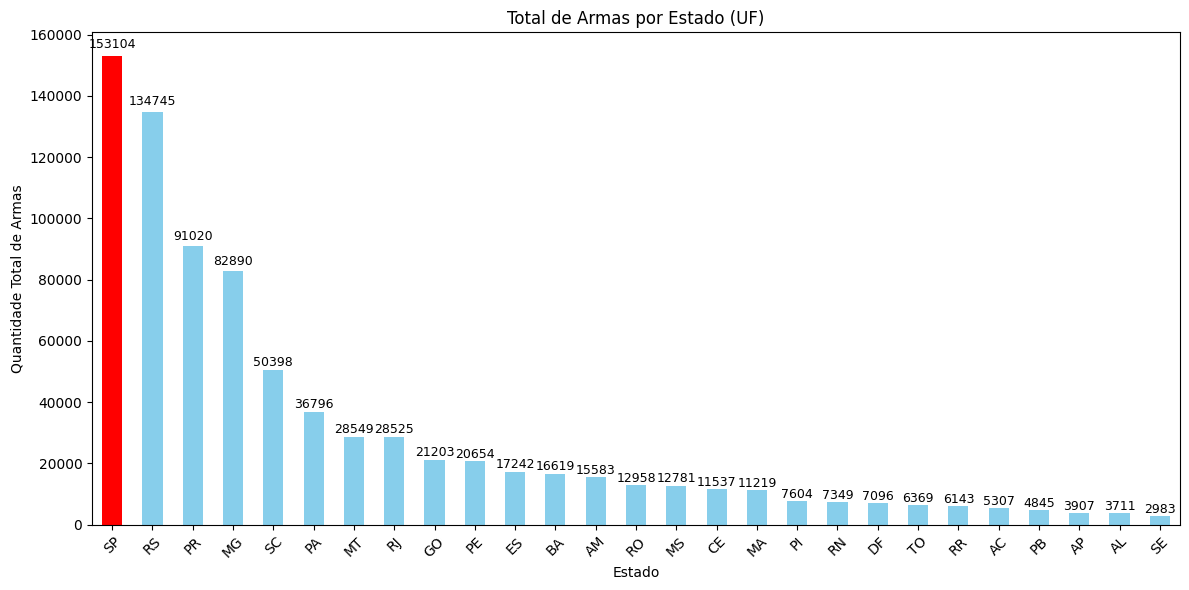

In [ ]:
# Agrupar por estado (UF) e somar o total de armas
df_por_estado = df.groupby('UF')['TOTAL'].sum().sort_values(ascending=False)

# Destacar o estado com maior número de armas
estado_topo = df_por_estado.idxmax()
cores = ['red' if uf == estado_topo else 'skyblue' for uf in df_por_estado.index]

# Criar o gráfico
plt.figure(figsize=(12, 6))
ax = df_por_estado.plot(kind='bar', color=cores)

plt.title('Total de Armas por Estado (UF)')
plt.xlabel('Estado')
plt.ylabel('Quantidade Total de Armas')
plt.xticks(rotation=45)

# Adicionar os valores em cima de cada barra
for i, valor in enumerate(df_por_estado):
    ax.text(i, valor + (valor * 0.01),   # posição (x,y)
            str(valor),                  # texto
            ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()



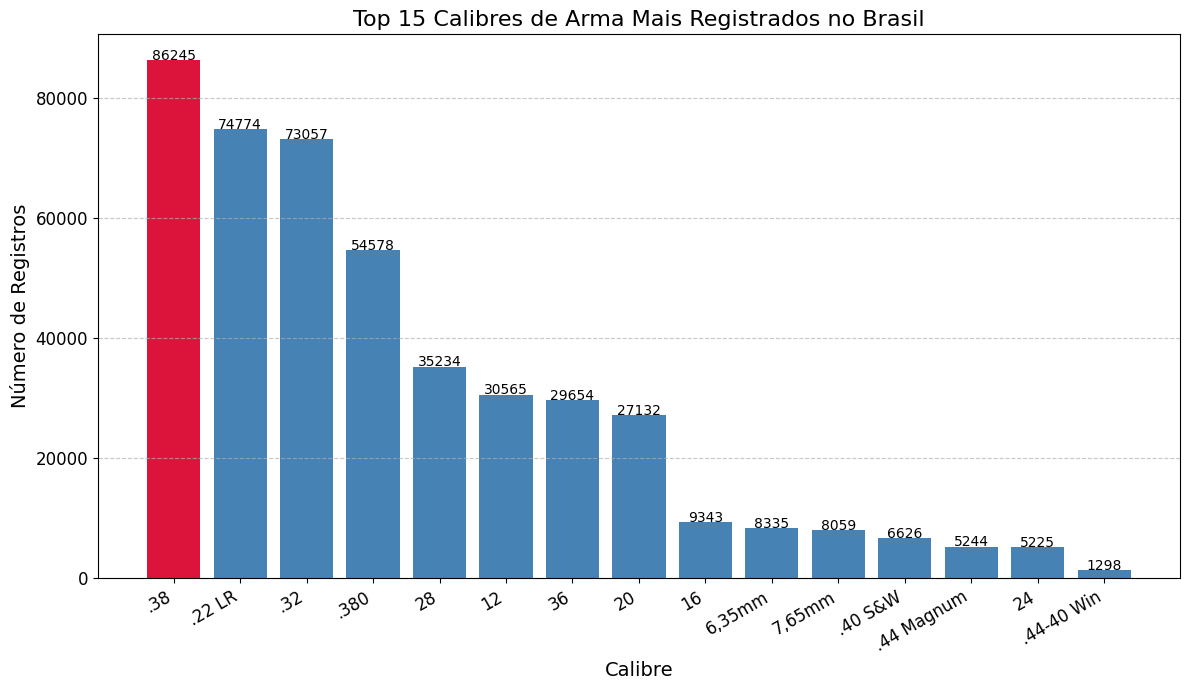

In [ ]:
#CALIBRES MAIS POPULARES NO BRASIL

# Contar os 15 calibres mais comuns
calibres = df['CALIBRE_ARMA'].value_counts().head(15)

# Identificar o calibre mais popular
calibre_topo = calibres.idxmax()
cores = ['crimson' if calibre == calibre_topo else 'steelblue' for calibre in calibres.index]

# Criar o gráfico
plt.figure(figsize=(12, 7))
bars = plt.bar(calibres.index, calibres.values, color=cores)

# Adicionar rótulos nas barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, int(yval), ha='center', fontsize=10)

# Personalização
plt.title('Top 15 Calibres de Arma Mais Registrados no Brasil', fontsize=16)
plt.xlabel('Calibre', fontsize=14)
plt.ylabel('Número de Registros', fontsize=14)
plt.xticks(rotation=30, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


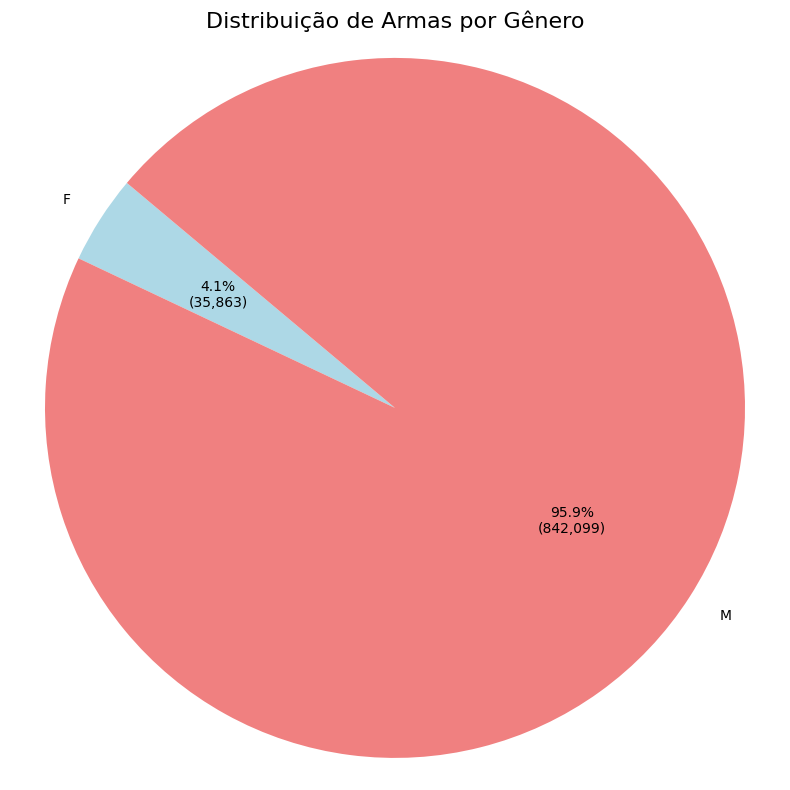

In [ ]:
#TOTAL ARMAS POR GÊNERO

# Agrupar por gênero e somar o total de armas
genero_total = df.groupby('SEXO')['TOTAL'].sum()

# Função para mostrar porcentagem e valor total
def formatar_autopct(pct):
    total = genero_total.sum()
    valor = int(round(pct * total / 100.0))
    return f'{pct:.1f}%\n({valor:,})'

# Criar o gráfico de pizza
plt.figure(figsize=(8, 8))
plt.pie(
    genero_total,
    labels=genero_total.index,
    autopct=formatar_autopct,
    startangle=140,
    colors=['lightblue', 'lightcoral', 'lightgreen']
)

plt.title('Distribuição de Armas por Gênero', fontsize=16)
plt.axis('equal')  # garante que o gráfico seja circular
plt.tight_layout()
plt.show()


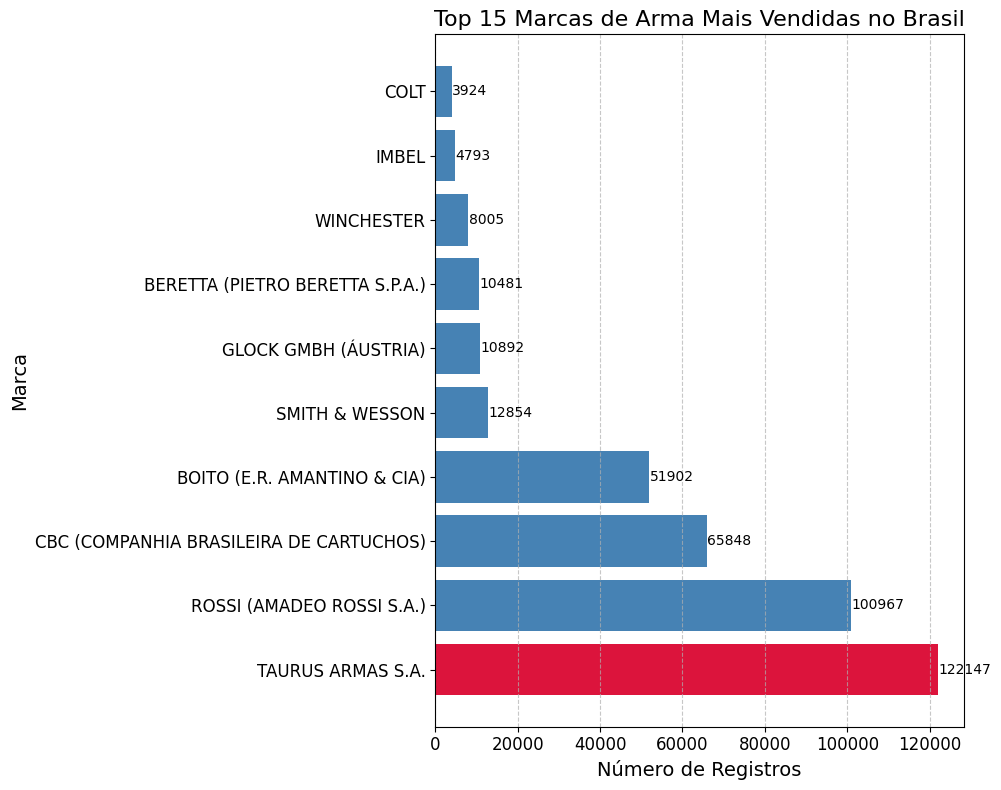

In [ ]:
#MARCAS MAIS VENDIDAS NO BRASIL

# Contar as 10 marcas mais frequentes
marcas = df['MARCA_ARMA'].value_counts().head(10)

# Identificar a marca mais popular
marca_topo = marcas.idxmax()
cores = ['crimson' if marca == marca_topo else 'steelblue' for marca in marcas.index]

# Criar o gráfico horizontal
plt.figure(figsize=(10, 8))
bars = plt.barh(marcas.index, marcas.values, color=cores)

# Adicionar rótulos nas barras
for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 100, bar.get_y() + bar.get_height()/2, int(xval), va='center', fontsize=10)

# Personalização
plt.title('Top 15 Marcas de Arma Mais Vendidas no Brasil', fontsize=16)
plt.xlabel('Número de Registros', fontsize=14)
plt.ylabel('Marca', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


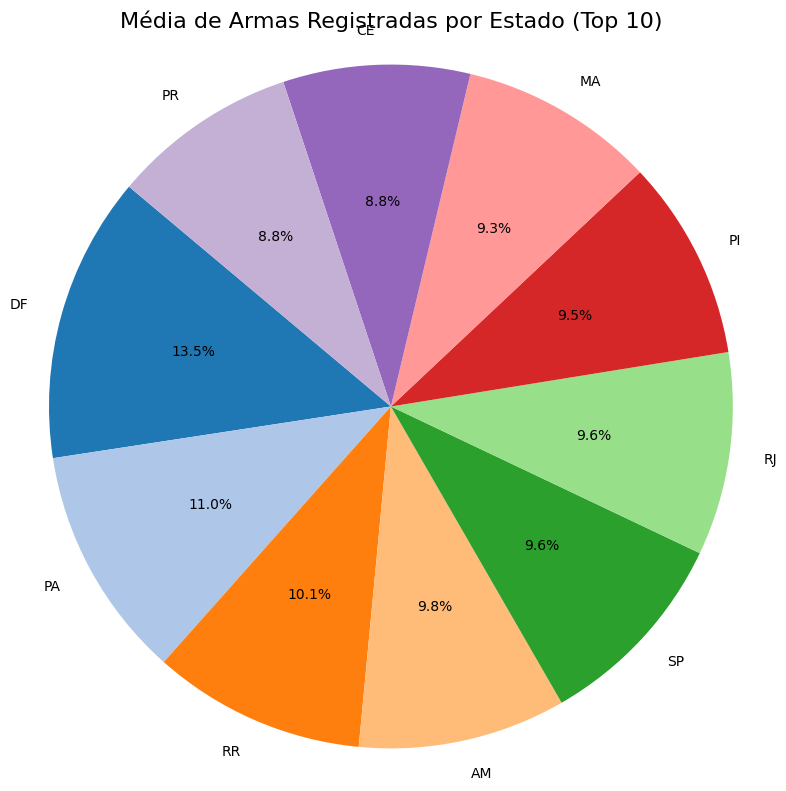

In [ ]:
#MEDIA DE ARMAS POR ESTADO

# Calcular a média de armas por estado
media_por_estado = df.groupby('UF')['TOTAL'].mean().sort_values(ascending=False)

# Selecionar os 10 estados com maior média
media_top10 = media_por_estado.head(10)

# Criar o gráfico de pizza
plt.figure(figsize=(8, 8))
plt.pie(
    media_top10,
    labels=media_top10.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.tab20.colors
)

plt.title('Média de Armas Registradas por Estado (Top 10)', fontsize=16)
plt.axis('equal')  # garante que o gráfico seja circular
plt.tight_layout()
plt.show()int64



/tmp/ipython-input-1345630742.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=contagem.index, y=contagem.values, palette="viridis")


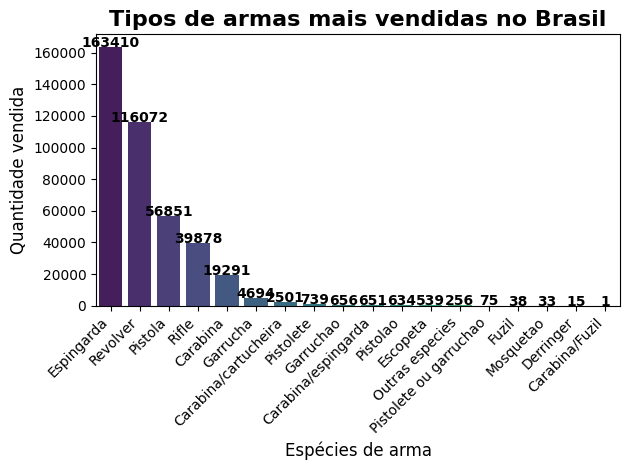

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Contagem das espécies de armas
contagem = df['ESPECIE_ARMA'].value_counts()

# Gráfico de barras com paleta de cores
sns.barplot(x=contagem.index, y=contagem.values, palette="viridis")

# Títulos e rótulos
plt.title("Tipos de armas mais vendidas no Brasil", fontsize=16, fontweight="bold")
plt.xlabel("Espécies de arma", fontsize=12)
plt.ylabel("Quantidade vendida", fontsize=12)

# Rotacionar os nomes para não ficarem sobrepostos
plt.xticks(rotation=45, ha="right")

# Mostrar valores em cima das barras
for i, v in enumerate(contagem.values):
    plt.text(i, v + 50, str(v), ha='center', fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()
